# Selección del umbral fijo para excluir el fondo

**Código auxiliar de selección del umbral de la región válida $R_i$**

Este notebook evalúa los umbrales enteros entre 0 y 25 para excluir regiones de baja intensidad conectadas con los bordes de las imágenes de entrenamiento de BRISC. Para cada umbral se calcula la región válida $R_{i,t}$, la conservación tumoral y la proporción de la imagen retenida.

El procedimiento reúne indicadores por imagen y para el conjunto completo, genera comparaciones visuales y registra las medidas utilizadas en la selección del umbral de intensidad.


## 1. Configuración

Se definen las rutas, los umbrales examinados, las semillas aleatorias y los parámetros de visualización.


In [1]:
from pathlib import Path
import json
import math
import platform
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from PIL import Image
from scipy import ndimage
from matplotlib.ticker import PercentFormatter


try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, **kwargs):
        return iterable

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)

def localizar_raiz_repositorio():
    """Localiza la raíz del repositorio desde JupyterLab o el directorio del notebook."""
    directorio_actual = Path.cwd().resolve()
    for candidato in (directorio_actual, *directorio_actual.parents):
        if (candidato / "notebooks" / "OE0").is_dir():
            return candidato
    raise FileNotFoundError(
        "No se encontró la raíz del repositorio. "
        "Se requiere la carpeta notebooks/OE0; ejecutar desde la raíz "
        "del repositorio o desde alguno de sus subdirectorios."
    )


REPO_ROOT = localizar_raiz_repositorio()
# Rutas relativas a la raíz del repositorio.
BASE_DIR = REPO_ROOT / "data" / "BRISC2025" / "segmentation_task" / "train"
IMAGES_DIR = BASE_DIR / "images"
MASKS_DIR = BASE_DIR / "masks"
OUTPUT_DIR = REPO_ROOT / "results" / "OE0" / "seleccion_umbral_Ri_BRISC"
TABLES_DIR = OUTPUT_DIR / "tablas"
FIGURES_DIR = OUTPUT_DIR / "figuras"

if not IMAGES_DIR.is_dir() or not MASKS_DIR.is_dir():
    raise FileNotFoundError(
        "No se encontró el conjunto BRISC depurado en "
        "data/BRISC2025/segmentation_task/train."
    )
for directory in (OUTPUT_DIR, TABLES_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# DATOS
# ------------------------------------------------------------

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
}

TUMOR_LABELS = {
    "gl": "Glioma",
    "me": "Meningioma",
    "pi": "Pituitario",
}

PLANE_LABELS = {
    "ax": "Axial",
    "co": "Coronal",
    "sa": "Sagital",
}

MASK_THRESHOLD = 127

# None utiliza todas las imágenes.
# Para pruebas rápidas puede utilizarse, por ejemplo, MAX_IMAGES = 500.
MAX_IMAGES = None
RANDOM_SEED = 2026

# ------------------------------------------------------------
# UMBRALES
# ------------------------------------------------------------

MIN_THRESHOLD = 0
MAX_THRESHOLD = 25

THRESHOLDS = list(
    range(
        MIN_THRESHOLD,
        MAX_THRESHOLD + 1,
    )
)

# ------------------------------------------------------------
# DECISIÓN Y COMPARACIONES
# ------------------------------------------------------------

REFERENCE_THRESHOLD = 9
SELECTED_THRESHOLD = 15
DETERIORATION_THRESHOLD = 16

EXAMPLE_THRESHOLDS = [
    0,
    REFERENCE_THRESHOLD,
    SELECTED_THRESHOLD,
]

N_RANDOM_EXAMPLES = 15
RANDOM_EXAMPLE_SEED = 2026
EXAMPLES_PER_FIGURE = 5

# ------------------------------------------------------------
# REVISIÓN VISUAL
# ------------------------------------------------------------

N_CRITICAL_IMAGES = 18
CASES_PER_FIGURE = 6
FIGURE_DPI = 180

CONNECTIVITY_STRUCTURE = np.ones(
    (3, 3),
    dtype=bool,
)


## 2. Indexación de imágenes y máscaras

Se identifican los pares imagen–máscara del conjunto de entrenamiento y se comprueba su correspondencia.


In [2]:
FILENAME_PATTERN = re.compile(
    r"brisc2025_train_(?P<image_id>\d+)_(?P<tumor_type>gl|me|pi)_(?P<plane>ax|co|sa)_t1",
    flags=re.IGNORECASE,
)


def index_directory(directory, role):
    if not directory.exists():
        raise FileNotFoundError(
            f"No existe la carpeta: {directory}"
        )

    records = []

    for path in sorted(directory.iterdir()):
        if not path.is_file():
            continue

        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        match = FILENAME_PATTERN.search(
            path.stem.lower()
        )

        if match is None:
            continue

        metadata = match.groupdict()

        records.append({
            "image_id": metadata["image_id"],
            "tumor_type": metadata["tumor_type"],
            "plane": metadata["plane"],
            f"{role}_path": str(path),
            f"{role}_filename": path.name,
        })

    indexed = pd.DataFrame(records)

    if indexed.empty:
        raise ValueError(
            f"No se encontraron archivos reconocibles en {directory}"
        )

    key = [
        "image_id",
        "tumor_type",
        "plane",
    ]

    duplicated = indexed.loc[
        indexed.duplicated(
            key,
            keep=False,
        )
    ]

    if not duplicated.empty:
        display(duplicated)

        raise ValueError(
            f"Se detectaron archivos duplicados en {directory}"
        )

    return indexed


images_df = index_directory(
    IMAGES_DIR,
    role="image",
)

masks_df = index_directory(
    MASKS_DIR,
    role="mask",
)

pairs_df = images_df.merge(
    masks_df,
    on=[
        "image_id",
        "tumor_type",
        "plane",
    ],
    how="inner",
)

pairs_df["tumor_label"] = (
    pairs_df["tumor_type"]
    .map(TUMOR_LABELS)
)

pairs_df["plane_label"] = (
    pairs_df["plane"]
    .map(PLANE_LABELS)
)

pairs_df = (
    pairs_df
    .sort_values([
        "tumor_type",
        "plane",
        "image_id",
    ])
    .reset_index(drop=True)
)

if MAX_IMAGES is not None:
    if MAX_IMAGES > len(pairs_df):
        raise ValueError(
            f"MAX_IMAGES={MAX_IMAGES} supera los "
            f"{len(pairs_df)} pares disponibles."
        )

    pairs_df = (
        pairs_df
        .sample(
            n=MAX_IMAGES,
            random_state=RANDOM_SEED,
            replace=False,
        )
        .sort_values([
            "tumor_type",
            "plane",
            "image_id",
        ])
        .reset_index(drop=True)
    )

print(f"Imágenes reconocidas: {len(images_df):,}")
print(f"Máscaras reconocidas: {len(masks_df):,}")
print(f"Pares utilizados: {len(pairs_df):,}")

display(
    pd.crosstab(
        pairs_df["tumor_label"],
        pairs_df["plane_label"],
        margins=True,
    )
)

pairs_df.to_csv(
    TABLES_DIR / "pares_utilizados.csv",
    index=False,
)

Imágenes reconocidas: 3,792
Máscaras reconocidas: 3,792
Pares utilizados: 3,792


plane_label,Axial,Coronal,Sagital,All
tumor_label,,,,
Glioma,394,430,323,1147
Meningioma,348,400,458,1206
Pituitario,424,502,513,1439
All,1166,1332,1294,3792


## 3. Definición de la región válida y evaluación de umbrales

Para cada imagen y umbral se cuantifican los píxeles tumorales conservados o excluidos y la proporción de región válida.


In [3]:
def load_grayscale(path):
    with Image.open(path) as image:
        return np.asarray(
            image.convert("L")
        )


def external_background_connected_to_border(
    image,
    threshold,
):
    """
    Detecta los píxeles con intensidad <= threshold conectados
    con algún borde mediante conectividad de ocho vecinos.
    """
    low_intensity = image <= threshold

    seed = np.zeros_like(
        low_intensity,
        dtype=bool,
    )

    seed[0, :] = low_intensity[0, :]
    seed[-1, :] = low_intensity[-1, :]
    seed[:, 0] = low_intensity[:, 0]
    seed[:, -1] = low_intensity[:, -1]

    return ndimage.binary_propagation(
        seed,
        structure=CONNECTIVITY_STRUCTURE,
        mask=low_intensity,
    )


def valid_mask_for_threshold(
    image,
    threshold,
):
    background = (
        external_background_connected_to_border(
            image,
            threshold=threshold,
        )
    )

    return ~background


evaluation_records = []
processing_errors = []

for row in tqdm(
    pairs_df.itertuples(index=False),
    total=len(pairs_df),
    desc="Evaluando umbrales 0–25",
):
    try:
        image = load_grayscale(
            row.image_path
        )

        mask_image = load_grayscale(
            row.mask_path
        )

        if image.shape != mask_image.shape:
            raise ValueError(
                "Dimensiones incompatibles: "
                f"{image.shape} y {mask_image.shape}"
            )

        tumor_mask = (
            mask_image > MASK_THRESHOLD
        )

        tumor_pixels = int(
            tumor_mask.sum()
        )

        if tumor_pixels == 0:
            raise ValueError(
                "La máscara tumoral no contiene píxeles positivos."
            )

        previous_lost_pixels = None
        previous_valid_mask = None

        for threshold in THRESHOLDS:
            valid_mask = valid_mask_for_threshold(
                image,
                threshold=threshold,
            )

            retained_tumor_pixels = int(
                np.logical_and(
                    tumor_mask,
                    valid_mask,
                ).sum()
            )

            lost_tumor_pixels = (
                tumor_pixels
                - retained_tumor_pixels
            )

            if previous_lost_pixels is None:
                newly_lost_tumor_pixels = np.nan
                changed_valid_fraction = np.nan
            else:
                newly_lost_tumor_pixels = (
                    lost_tumor_pixels
                    - previous_lost_pixels
                )

                changed_valid_fraction = float(
                    np.logical_xor(
                        previous_valid_mask,
                        valid_mask,
                    ).mean()
                )

            evaluation_records.append({
                "image_id": row.image_id,
                "tumor_type": row.tumor_type,
                "tumor_label": row.tumor_label,
                "plane": row.plane,
                "plane_label": row.plane_label,
                "image_path": row.image_path,
                "mask_path": row.mask_path,
                "threshold": threshold,
                "tumor_pixels": tumor_pixels,
                "retained_tumor_pixels": (
                    retained_tumor_pixels
                ),
                "lost_tumor_pixels": (
                    lost_tumor_pixels
                ),
                "newly_lost_tumor_pixels": (
                    newly_lost_tumor_pixels
                ),
                "tumor_retention": (
                    retained_tumor_pixels
                    / tumor_pixels
                ),
                "valid_fraction": float(
                    valid_mask.mean()
                ),
                "changed_valid_fraction": (
                    changed_valid_fraction
                ),
            })

            previous_lost_pixels = (
                lost_tumor_pixels
            )

            previous_valid_mask = (
                valid_mask
            )

    except Exception as error:
        processing_errors.append({
            "image_id": row.image_id,
            "image_path": row.image_path,
            "mask_path": row.mask_path,
            "error_type": type(error).__name__,
            "error_message": str(error),
        })

evaluation_df = pd.DataFrame(
    evaluation_records
)

errors_df = pd.DataFrame(
    processing_errors
)

if evaluation_df.empty:
    raise RuntimeError(
        "No fue posible evaluar ninguna imagen."
    )

evaluation_df.to_csv(
    TABLES_DIR / "resultados_por_imagen_y_umbral.csv",
    index=False,
)

errors_df.to_csv(
    TABLES_DIR / "errores_procesamiento.csv",
    index=False,
)

print(
    f"Imágenes procesadas: "
    f"{evaluation_df['image_id'].nunique():,}"
)

print(
    f"Imágenes con error: "
    f"{len(errors_df):,}"
)

Evaluando umbrales 0–25:   0%|          | 0/3792 [00:00<?, ?it/s]

Imágenes procesadas: 3,792
Imágenes con error: 0


## 4. Resumen por umbral

Se agregan las pérdidas tumorales, el número de imágenes afectadas y las medidas de conservación global y mínima.


In [4]:
first_loss_thresholds = (
    evaluation_df.loc[
        evaluation_df[
            "lost_tumor_pixels"
        ]
        > 0
    ]
    .groupby(
        "image_id",
        observed=True,
    )["threshold"]
    .min()
)

newly_affected_counts = (
    first_loss_thresholds
    .value_counts()
    .reindex(
        THRESHOLDS,
        fill_value=0,
    )
)

summary_df = (
    evaluation_df
    .groupby(
        "threshold",
        observed=True,
    )
    .agg(
        n_images=(
            "image_id",
            "count",
        ),
        total_tumor_pixels=(
            "tumor_pixels",
            "sum",
        ),
        total_retained_tumor_pixels=(
            "retained_tumor_pixels",
            "sum",
        ),
        total_lost_tumor_pixels=(
            "lost_tumor_pixels",
            "sum",
        ),
        newly_lost_tumor_pixels=(
            "newly_lost_tumor_pixels",
            "sum",
        ),
        images_with_tumor_loss=(
            "lost_tumor_pixels",
            lambda x: int(
                (x > 0).sum()
            ),
        ),
        minimum_tumor_retention=(
            "tumor_retention",
            "min",
        ),
        p01_tumor_retention=(
            "tumor_retention",
            lambda x: x.quantile(0.01),
        ),
        median_valid_fraction=(
            "valid_fraction",
            "median",
        ),
        p95_changed_valid_fraction=(
            "changed_valid_fraction",
            lambda x: x.quantile(0.95),
        ),
    )
    .reset_index()
    .sort_values("threshold")
    .reset_index(drop=True)
)

summary_df[
    "global_tumor_retention"
] = (
    summary_df[
        "total_retained_tumor_pixels"
    ]
    / summary_df[
        "total_tumor_pixels"
    ]
)

summary_df[
    "newly_affected_images"
] = (
    summary_df["threshold"]
    .map(
        newly_affected_counts
    )
    .astype(int)
)

summary_df[
    "newly_lost_fraction_of_dataset_tumor"
] = (
    summary_df[
        "newly_lost_tumor_pixels"
    ]
    / summary_df[
        "total_tumor_pixels"
    ]
)

summary_df.to_csv(
    TABLES_DIR / "resumen_por_umbral.csv",
    index=False,
)

display(
    summary_df
)

,threshold,n_images,total_tumor_pixels,total_retained_tumor_pixels,total_lost_tumor_pixels,newly_lost_tumor_pixels,images_with_tumor_loss,minimum_tumor_retention,p01_tumor_retention,median_valid_fraction,p95_changed_valid_fraction,global_tumor_retention,newly_affected_images,newly_lost_fraction_of_dataset_tumor
0,0,3792,15496552,15496552,0,0.0,0,1.000000,1.0,0.913872,NaN,1.000000,0,0.000000e+00
1,1,3792,15496552,15496552,0,0.0,0,1.000000,1.0,0.905571,0.087299,1.000000,0,0.000000e+00
2,2,3792,15496552,15496552,0,0.0,0,1.000000,1.0,0.837294,0.169728,1.000000,0,0.000000e+00
3,3,3792,15496552,15496552,0,0.0,0,1.000000,1.0,0.766251,0.154636,1.000000,0,0.000000e+00
4,4,3792,15496552,15496552,0,0.0,0,1.000000,1.0,0.694977,0.120492,1.000000,0,0.000000e+00
5,5,3792,15496552,15496552,0,0.0,0,1.000000,1.0,0.639318,0.089214,1.000000,0,0.000000e+00
6,6,3792,15496552,15496552,0,0.0,0,1.000000,1.0,0.609957,0.085017,1.000000,0,0.000000e+00
7,7,3792,15496552,15496552,0,0.0,0,1.000000,1.0,0.590427,0.080947,1.000000,0,0.000000e+00
8,8,3792,15496552,15496552,0,0.0,0,1.000000,1.0,0.579620,0.067469,1.000000,0,0.000000e+00
9,9,3792,15496552,15496552,0,0.0,0,1.000000,1.0,0.572870,0.052693,1.000000,0,0.000000e+00


## 5. Comparación de umbrales de referencia

Se resumen los indicadores correspondientes a los umbrales 0, 9, 15 y 16.


In [5]:
DECISION_THRESHOLDS = [
    0,
    REFERENCE_THRESHOLD,
    SELECTED_THRESHOLD,
    DETERIORATION_THRESHOLD,
]

decision_table_df = (
    summary_df.loc[
        summary_df["threshold"].isin(
            DECISION_THRESHOLDS
        ),
        [
            "threshold",
            "total_tumor_pixels",
            "total_lost_tumor_pixels",
            "newly_lost_tumor_pixels",
            "images_with_tumor_loss",
            "newly_affected_images",
            "global_tumor_retention",
            "minimum_tumor_retention",
            "median_valid_fraction",
            "p95_changed_valid_fraction",
        ],
    ]
    .copy()
    .reset_index(drop=True)
)

decision_table_df[
    "global_tumor_retention_percent"
] = (
    100
    * decision_table_df[
        "global_tumor_retention"
    ]
)

decision_table_df[
    "minimum_tumor_retention_percent"
] = (
    100
    * decision_table_df[
        "minimum_tumor_retention"
    ]
)

decision_table_df[
    "median_valid_fraction_percent"
] = (
    100
    * decision_table_df[
        "median_valid_fraction"
    ]
)

decision_table_df.to_csv(
    TABLES_DIR
    / "comparacion_umbrales_0_9_15_16.csv",
    index=False,
)

display(
    decision_table_df
)

,threshold,total_tumor_pixels,total_lost_tumor_pixels,newly_lost_tumor_pixels,images_with_tumor_loss,newly_affected_images,global_tumor_retention,minimum_tumor_retention,median_valid_fraction,p95_changed_valid_fraction,global_tumor_retention_percent,minimum_tumor_retention_percent,median_valid_fraction_percent
0,0,15496552,0,0.0,0,0,1.000000,1.000000,0.913872,NaN,100.000000,100.000000,91.387177
1,9,15496552,0,0.0,0,0,1.000000,1.000000,0.572870,0.052693,100.000000,100.000000,57.287025
2,15,15496552,30,5.0,2,1,0.999998,0.993681,0.557215,0.005628,99.999806,99.368088,55.721474
3,16,15496552,1706,1676.0,3,1,0.999890,0.616114,0.555346,0.004837,99.988991,61.611374,55.534554


In [6]:
row_9 = (
    summary_df.loc[
        summary_df["threshold"]
        == REFERENCE_THRESHOLD
    ]
    .iloc[0]
)

row_15 = (
    summary_df.loc[
        summary_df["threshold"]
        == SELECTED_THRESHOLD
    ]
    .iloc[0]
)

row_16 = (
    summary_df.loc[
        summary_df["threshold"]
        == DETERIORATION_THRESHOLD
    ]
    .iloc[0]
)

previous_increment_max = float(
    summary_df.loc[
        summary_df["threshold"]
        < DETERIORATION_THRESHOLD,
        "newly_lost_tumor_pixels",
    ].max()
)

increment_at_15 = float(
    row_15[
        "newly_lost_tumor_pixels"
    ]
)

increment_at_16 = float(
    row_16[
        "newly_lost_tumor_pixels"
    ]
)

ratio_16_to_15 = (
    increment_at_16
    / increment_at_15
    if increment_at_15 > 0
    else np.inf
)

ratio_16_to_previous_max = (
    increment_at_16
    / previous_increment_max
    if previous_increment_max > 0
    else np.inf
)

valid_area_reduction_9_to_15 = (
    row_9["median_valid_fraction"]
    - row_15["median_valid_fraction"]
)

print(
    "Indicadores principales"
)

print(
    f"- Píxeles tumorales perdidos con umbral 15: "
    f"{int(row_15['total_lost_tumor_pixels']):,}"
)

print(
    f"- Imágenes con pérdida tumoral en 15: "
    f"{int(row_15['images_with_tumor_loss']):,}"
)

print(
    f"- Conservación tumoral global en 15: "
    f"{row_15['global_tumor_retention']:.8%}"
)

print(
    f"- Conservación mínima por imagen en 15: "
    f"{row_15['minimum_tumor_retention']:.6%}"
)

print(
    f"- Píxeles tumorales nuevos perdidos al pasar a 16: "
    f"{int(increment_at_16):,}"
)

print(
    f"- Conservación mínima por imagen en 16: "
    f"{row_16['minimum_tumor_retention']:.6%}"
)

print(
    f"- El incremento de pérdida en 16 es "
    f"{ratio_16_to_15:.1f} veces el incremento observado en 15."
)

print(
    f"- El incremento de pérdida en 16 es "
    f"{ratio_16_to_previous_max:.1f} veces el mayor incremento previo."
)

print(
    f"- La mediana de la región válida disminuye "
    f"{valid_area_reduction_9_to_15:.2%} al pasar de 9 a 15."
)

Indicadores principales
- Píxeles tumorales perdidos con umbral 15: 30
- Imágenes con pérdida tumoral en 15: 2
- Conservación tumoral global en 15: 99.99980641%
- Conservación mínima por imagen en 15: 99.368088%
- Píxeles tumorales nuevos perdidos al pasar a 16: 1,676
- Conservación mínima por imagen en 16: 61.611374%
- El incremento de pérdida en 16 es 335.2 veces el incremento observado en 15.
- El incremento de pérdida en 16 es 186.2 veces el mayor incremento previo.
- La mediana de la región válida disminuye 1.57% al pasar de 9 a 15.


## 6. Pérdida tumoral acumulada

Se representa la cantidad total de píxeles tumorales excluidos para cada umbral.


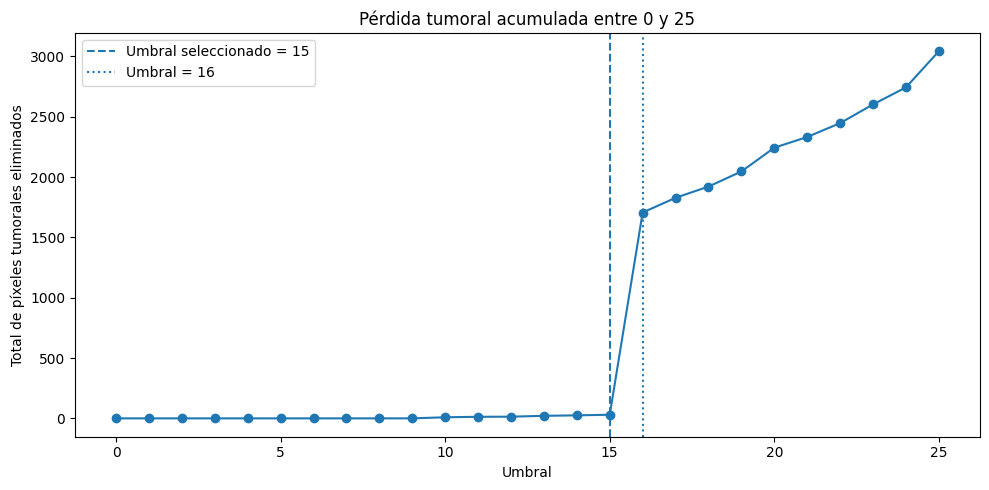

In [7]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    summary_df["threshold"],
    summary_df[
        "total_lost_tumor_pixels"
    ],
    marker="o",
)

plt.axvline(
    SELECTED_THRESHOLD,
    linestyle="--",
    label=(
        f"Umbral seleccionado = "
        f"{SELECTED_THRESHOLD}"
    ),
)

plt.axvline(
    DETERIORATION_THRESHOLD,
    linestyle=":",
    label=(
        f"Umbral = "
        f"{DETERIORATION_THRESHOLD}"
    ),
)

plt.xlabel("Umbral")
plt.ylabel(
    "Total de píxeles tumorales eliminados"
)
plt.title(
    "Pérdida tumoral acumulada entre 0 y 25"
)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "perdida_tumoral_acumulada.png",
    dpi=FIGURE_DPI,
    bbox_inches="tight",
)

plt.show()

## 7. Pérdida tumoral adicional

Se representa el incremento de píxeles tumorales excluidos al aumentar el umbral en una unidad.


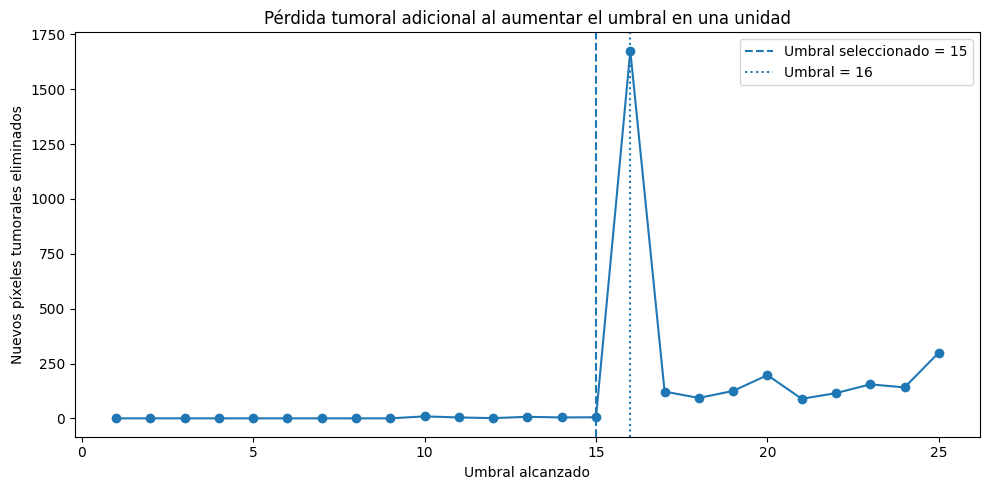

In [8]:
increment_rows = (
    summary_df.loc[
        summary_df["threshold"] > MIN_THRESHOLD
    ]
    .copy()
)

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    increment_rows["threshold"],
    increment_rows[
        "newly_lost_tumor_pixels"
    ],
    marker="o",
)

plt.axvline(
    SELECTED_THRESHOLD,
    linestyle="--",
    label=(
        f"Umbral seleccionado = "
        f"{SELECTED_THRESHOLD}"
    ),
)

plt.axvline(
    DETERIORATION_THRESHOLD,
    linestyle=":",
    label=(
        f"Umbral = "
        f"{DETERIORATION_THRESHOLD}"
    ),
)

plt.xlabel("Umbral alcanzado")
plt.ylabel(
    "Nuevos píxeles tumorales eliminados"
)
plt.title(
    "Pérdida tumoral adicional al aumentar "
    "el umbral en una unidad"
)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "incremento_perdida_tumoral.png",
    dpi=FIGURE_DPI,
    bbox_inches="tight",
)

plt.show()

## 8. Primer umbral con pérdida tumoral

Se cuantifica el número de imágenes que presentan pérdida tumoral por primera vez en cada umbral.


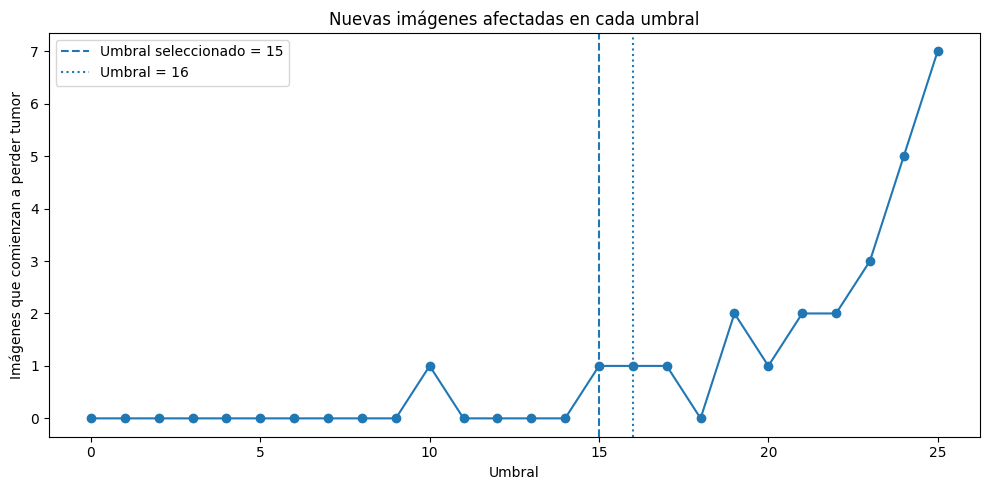

In [9]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    summary_df["threshold"],
    summary_df[
        "newly_affected_images"
    ],
    marker="o",
)

plt.axvline(
    SELECTED_THRESHOLD,
    linestyle="--",
    label=(
        f"Umbral seleccionado = "
        f"{SELECTED_THRESHOLD}"
    ),
)

plt.axvline(
    DETERIORATION_THRESHOLD,
    linestyle=":",
    label=(
        f"Umbral = "
        f"{DETERIORATION_THRESHOLD}"
    ),
)

plt.xlabel("Umbral")
plt.ylabel(
    "Imágenes que comienzan a perder tumor"
)
plt.title(
    "Nuevas imágenes afectadas en cada umbral"
)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "nuevas_imagenes_afectadas.png",
    dpi=FIGURE_DPI,
    bbox_inches="tight",
)

plt.show()

## 9. Conservación tumoral global y mínima

Se comparan las proporciones de píxeles tumorales conservados en el conjunto y en la imagen más afectada.


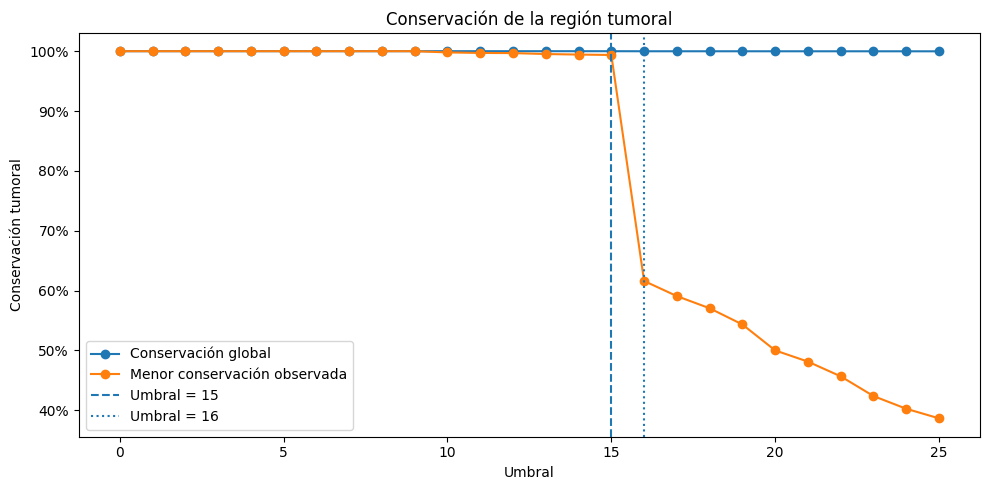

In [10]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    summary_df["threshold"],
    100 * summary_df[
        "global_tumor_retention"
    ],
    marker="o",
    label="Conservación global",
)

plt.plot(
    summary_df["threshold"],
    100 * summary_df[
        "minimum_tumor_retention"
    ],
    marker="o",
    label="Menor conservación observada",
)

plt.axvline(
    SELECTED_THRESHOLD,
    linestyle="--",
    label=(
        f"Umbral = "
        f"{SELECTED_THRESHOLD}"
    ),
)

plt.axvline(
    DETERIORATION_THRESHOLD,
    linestyle=":",
    label=(
        f"Umbral = "
        f"{DETERIORATION_THRESHOLD}"
    ),
)

plt.xlabel("Umbral")
plt.ylabel("Conservación tumoral")

# El eje Y ahora trabaja entre 0 y 100
plt.gca().yaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)

plt.title(
    "Conservación de la región tumoral"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "conservacion_tumoral.png",
    dpi=FIGURE_DPI,
    bbox_inches="tight",
)

plt.show()

## 10. Comparación visual de umbrales

Se obtiene una muestra aleatoria reproducible y se visualizan las regiones válidas para los umbrales 0, 9 y 15, con los contornos anatómicos y tumorales.


In [11]:
if len(pairs_df) < N_RANDOM_EXAMPLES:
    raise ValueError(
        f"Solo existen {len(pairs_df)} imágenes, "
        f"pero se solicitaron {N_RANDOM_EXAMPLES}."
    )

random_examples_df = (
    pairs_df
    .sample(
        n=N_RANDOM_EXAMPLES,
        random_state=RANDOM_EXAMPLE_SEED,
        replace=False,
    )
    .reset_index(drop=True)
)

random_examples_df.insert(
    0,
    "example_order",
    np.arange(
        1,
        len(random_examples_df) + 1,
    ),
)

random_examples_df.to_csv(
    TABLES_DIR
    / "muestra_aleatoria_umbrales_0_9_15.csv",
    index=False,
)

display(
    random_examples_df[
        [
            "example_order",
            "image_id",
            "tumor_label",
            "plane_label",
            "image_path",
        ]
    ]
)

,example_order,image_id,tumor_label,plane_label,image_path
0,1,01686,Meningioma,Coronal,K:\Tesis\Github\data\BRISC2025\segmentation_ta...
1,2,01006,Glioma,Sagital,K:\Tesis\Github\data\BRISC2025\segmentation_ta...
2,3,00497,Glioma,Coronal,K:\Tesis\Github\data\BRISC2025\segmentation_ta...
3,4,03874,Pituitario,Axial,K:\Tesis\Github\data\BRISC2025\segmentation_ta...
4,5,04251,Pituitario,Coronal,K:\Tesis\Github\data\BRISC2025\segmentation_ta...
5,6,02070,Meningioma,Sagital,K:\Tesis\Github\data\BRISC2025\segmentation_ta...
6,7,00237,Glioma,Axial,K:\Tesis\Github\data\BRISC2025\segmentation_ta...
7,8,04437,Pituitario,Coronal,K:\Tesis\Github\data\BRISC2025\segmentation_ta...
8,9,01958,Meningioma,Coronal,K:\Tesis\Github\data\BRISC2025\segmentation_ta...
9,10,04756,Pituitario,Sagital,K:\Tesis\Github\data\BRISC2025\segmentation_ta...


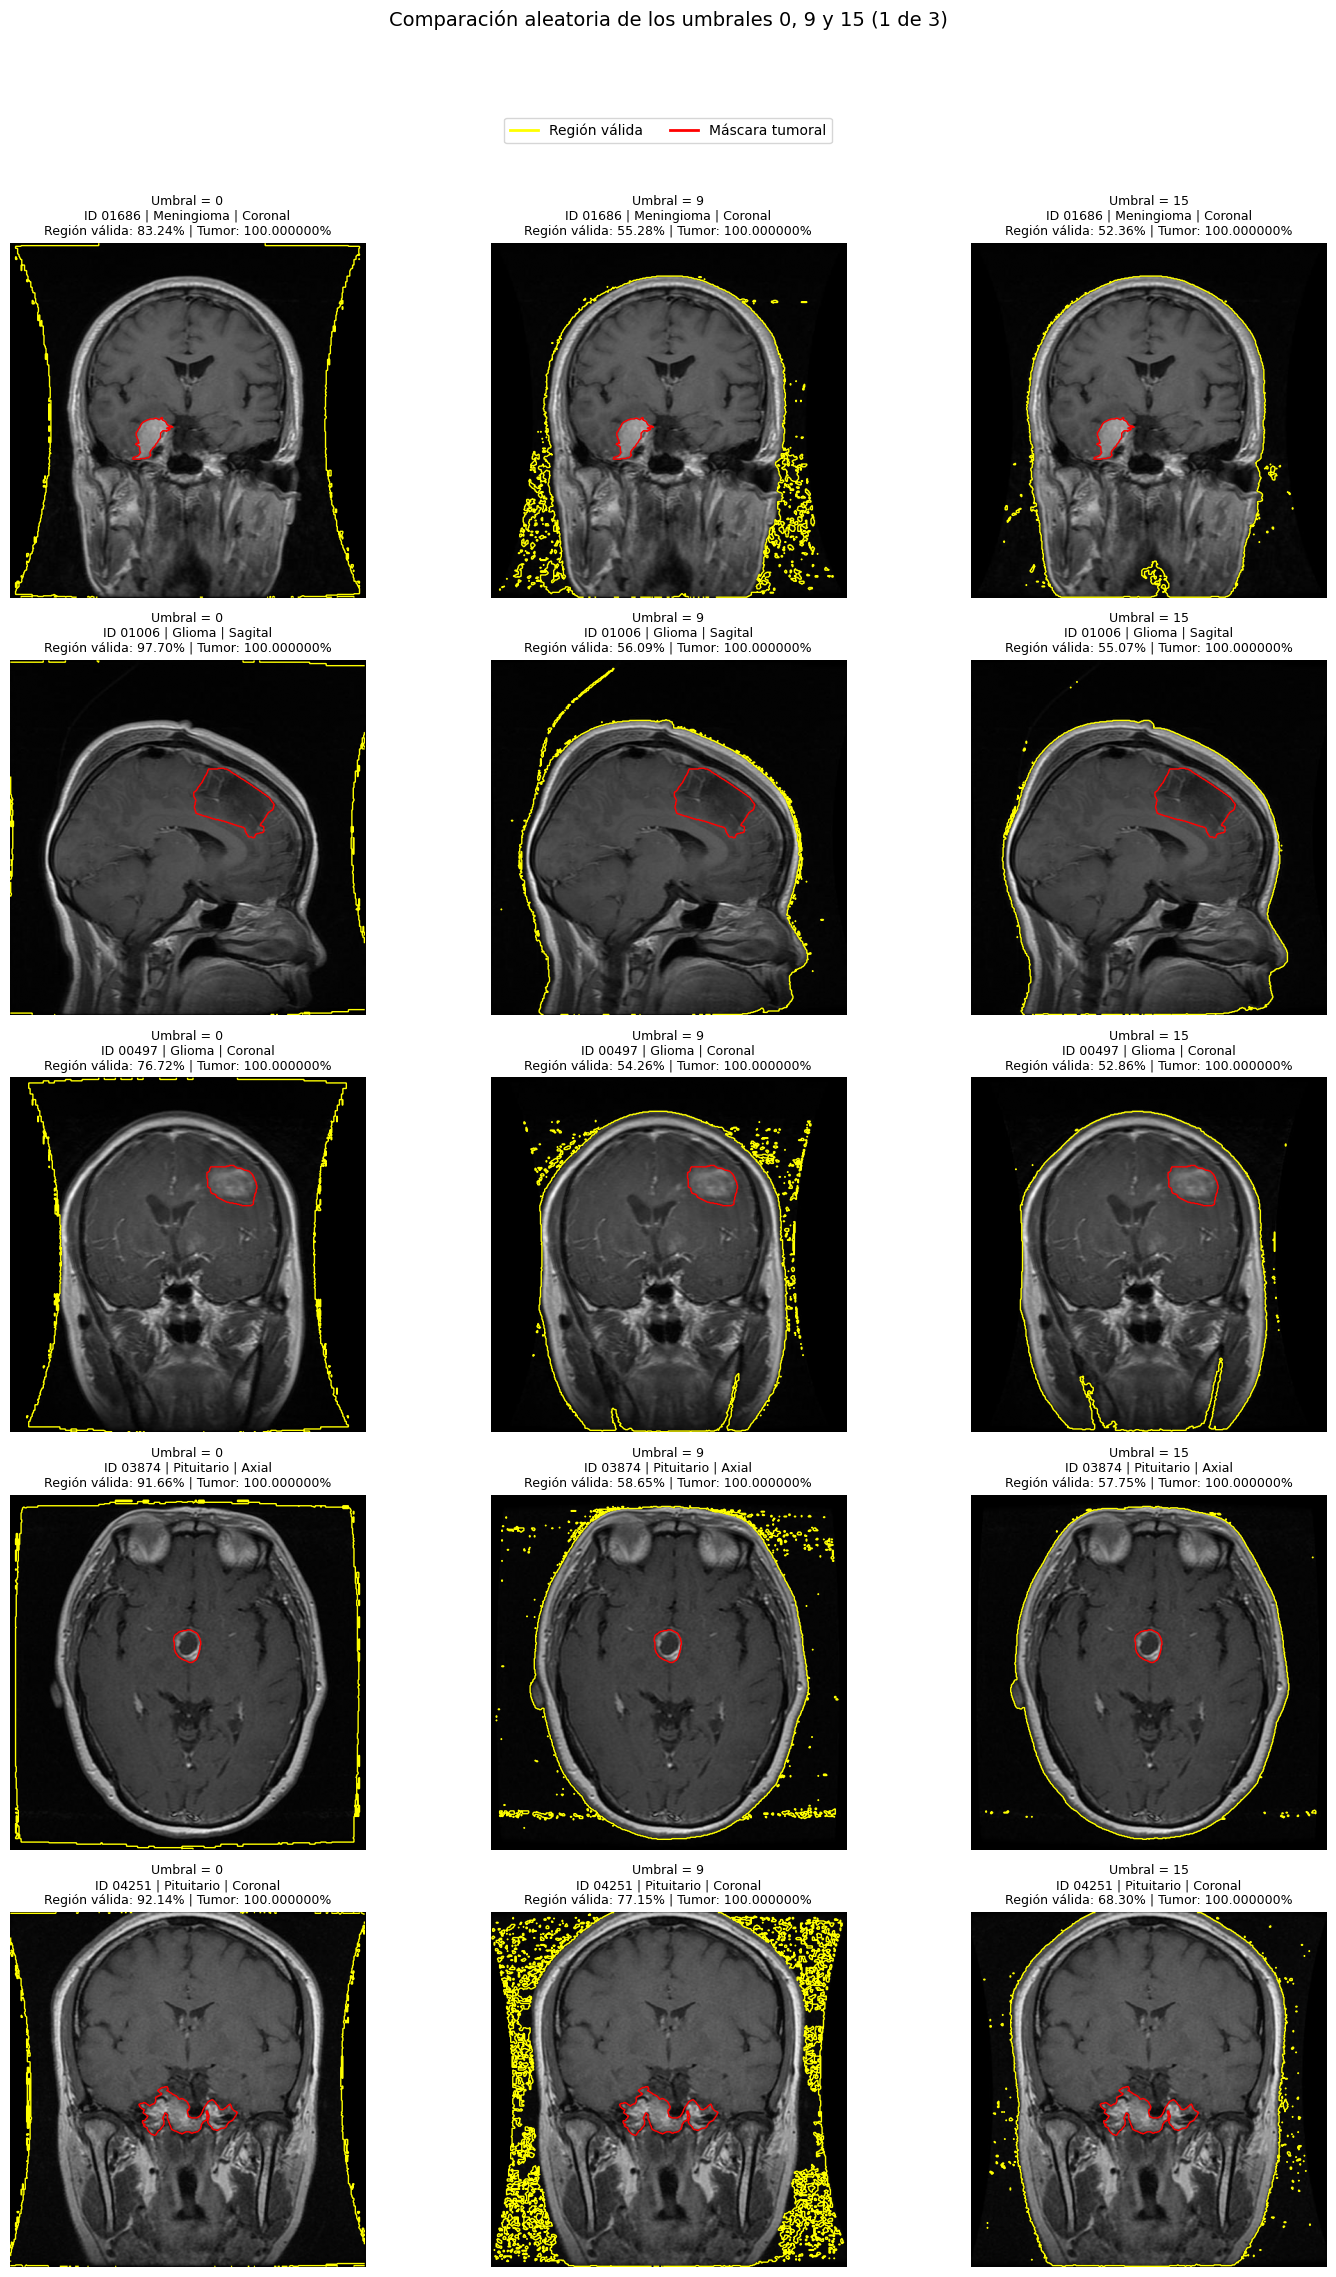

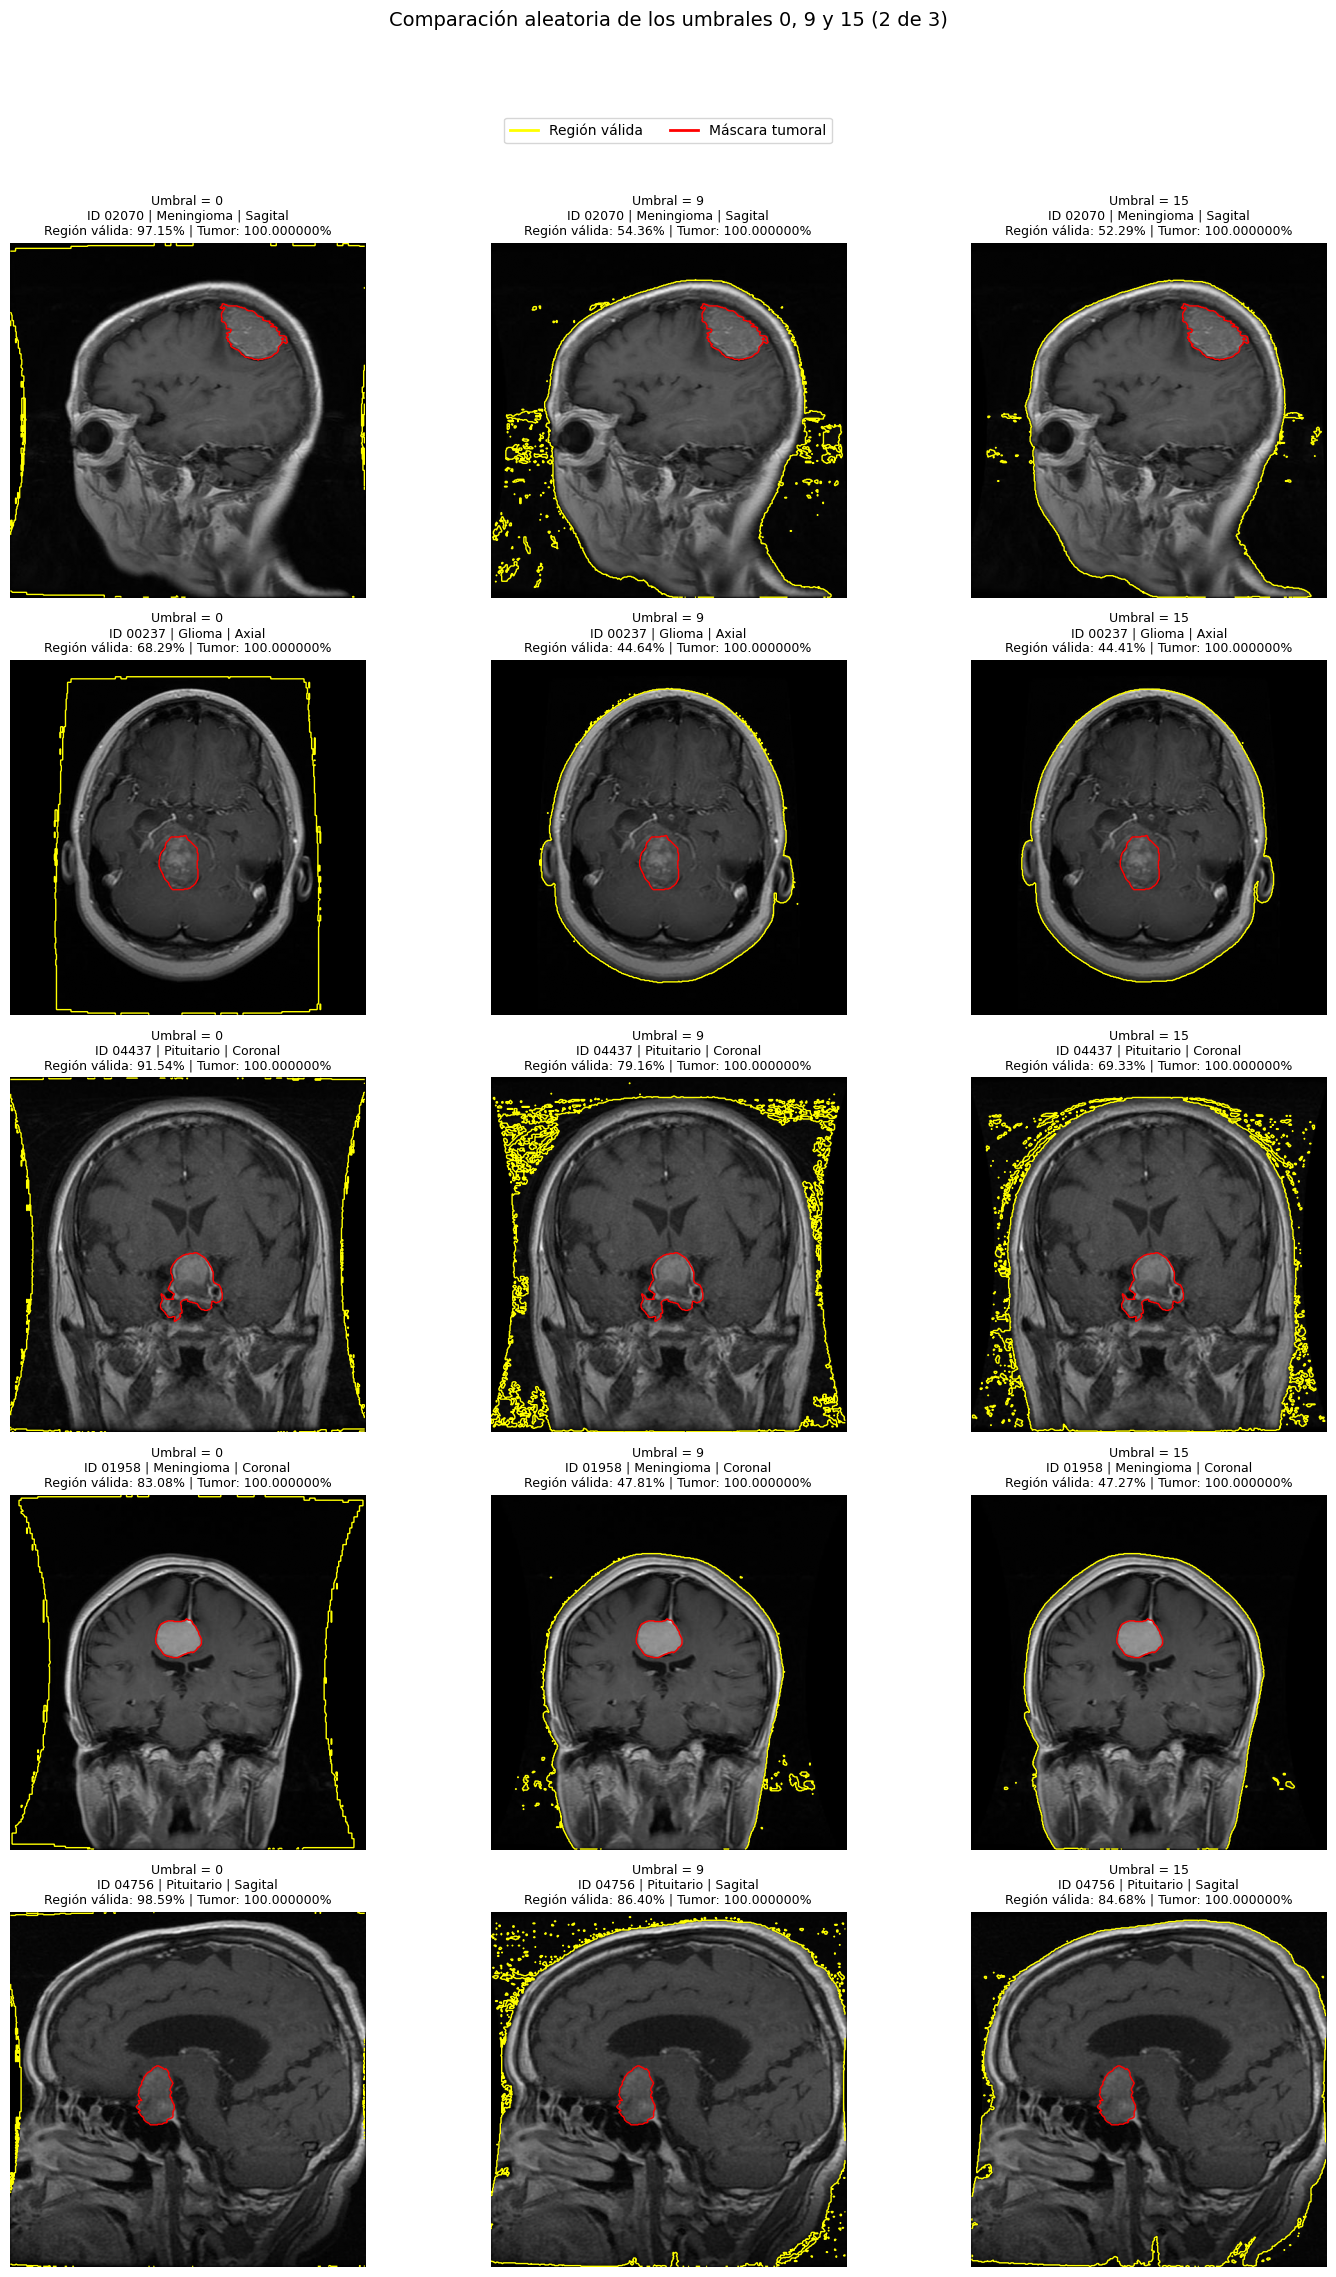

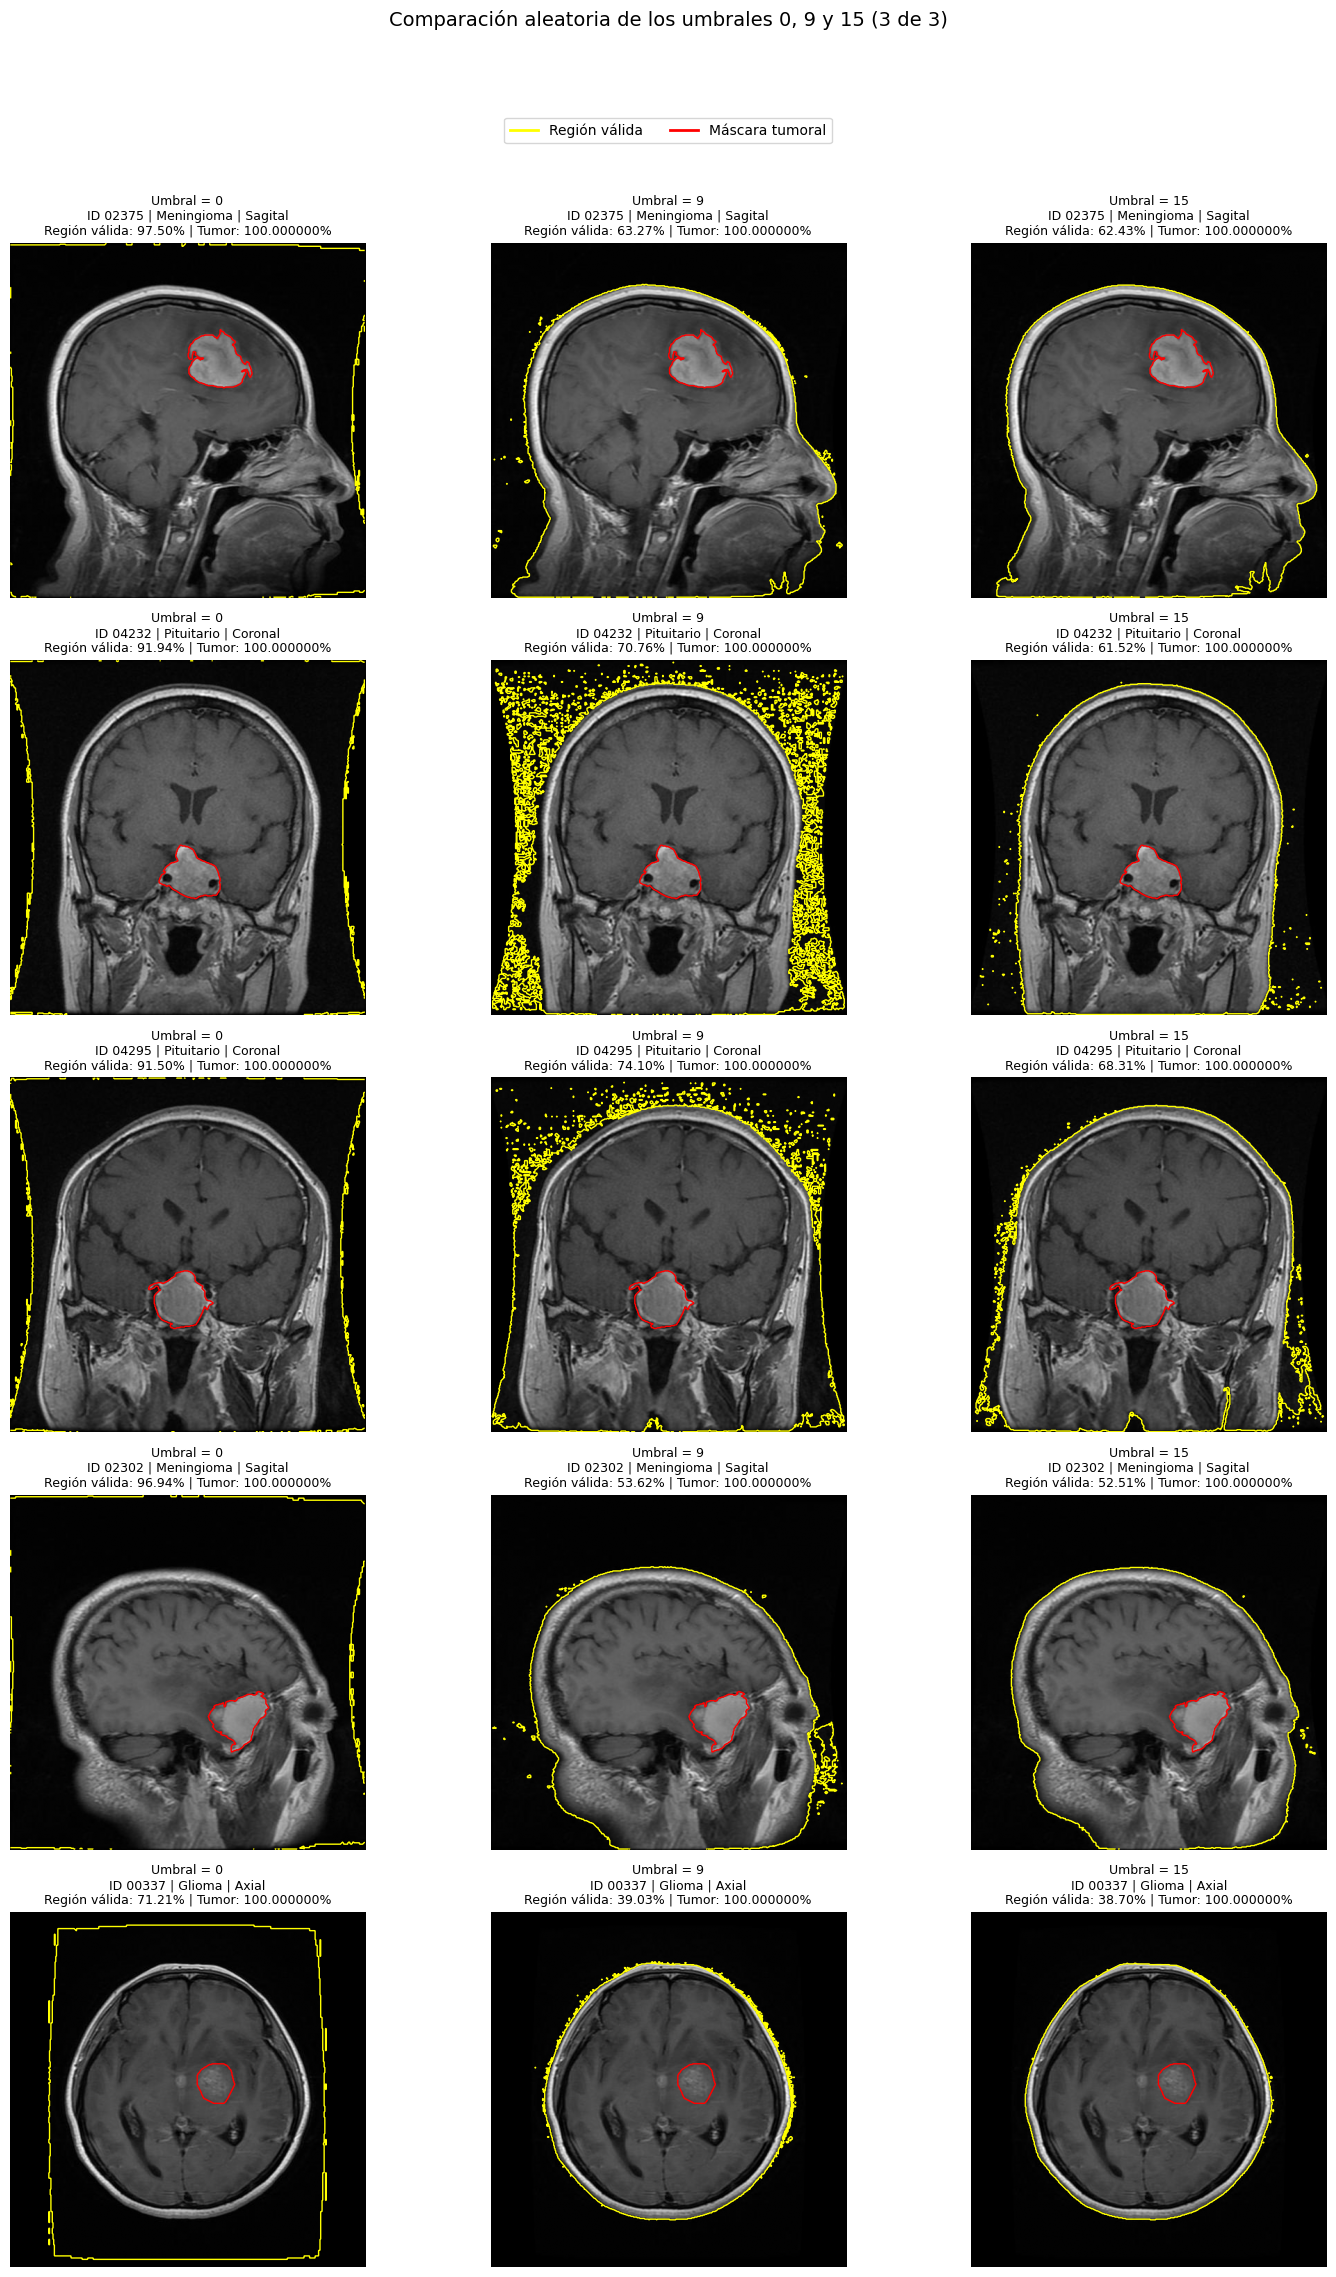

In [12]:
from matplotlib.lines import Line2D


def draw_threshold_example(
    axis,
    image,
    tumor_mask,
    threshold,
    title_information,
):
    valid_mask = valid_mask_for_threshold(
        image,
        threshold=threshold,
    )

    retained_tumor_pixels = int(
        np.logical_and(
            tumor_mask,
            valid_mask,
        ).sum()
    )

    total_tumor_pixels = int(
        tumor_mask.sum()
    )

    tumor_retention = (
        retained_tumor_pixels
        / total_tumor_pixels
    )

    axis.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=255,
    )

    axis.contour(
        valid_mask.astype(float),
        levels=[0.5],
        colors="yellow",
        linewidths=1,
        linestyles="solid",
    )

    axis.contour(
        tumor_mask.astype(float),
        levels=[0.5],
        colors="red",
        linewidths=1,
        linestyles="solid",
    )

    axis.set_title(
        f"Umbral = {threshold}\n"
        f"{title_information}\n"
        f"Región válida: "
        f"{valid_mask.mean():.2%} | "
        f"Tumor: {tumor_retention:.6%}",
        fontsize=9,
    )

    axis.axis("off")


n_example_figures = math.ceil(
    N_RANDOM_EXAMPLES
    / EXAMPLES_PER_FIGURE
)

for figure_index in range(
    n_example_figures
):
    start = (
        figure_index
        * EXAMPLES_PER_FIGURE
    )

    stop = min(
        start + EXAMPLES_PER_FIGURE,
        N_RANDOM_EXAMPLES,
    )

    batch = random_examples_df.iloc[
        start:stop
    ]

    figure, axes = plt.subplots(
        nrows=len(batch),
        ncols=len(EXAMPLE_THRESHOLDS),
        figsize=(
            15,
            4.5 * len(batch),
        ),
    )

    if len(batch) == 1:
        axes = np.array([
            axes
        ])

    for row_position, row in enumerate(
        batch.itertuples(index=False)
    ):
        image = load_grayscale(
            row.image_path
        )

        mask_image = load_grayscale(
            row.mask_path
        )

        tumor_mask = (
            mask_image > MASK_THRESHOLD
        )

        title_information = (
            f"ID {row.image_id} | "
            f"{row.tumor_label} | "
            f"{row.plane_label}"
        )

        for column_position, threshold in enumerate(
            EXAMPLE_THRESHOLDS
        ):
            draw_threshold_example(
                axis=axes[
                    row_position,
                    column_position,
                ],
                image=image,
                tumor_mask=tumor_mask,
                threshold=threshold,
                title_information=(
                    title_information
                ),
            )

    legend_elements = [
        Line2D(
            [0],
            [0],
            color="yellow",
            linewidth=2,
            linestyle="solid",
            label="Región válida",
        ),
        Line2D(
            [0],
            [0],
            color="red",
            linewidth=2,
            linestyle="solid",
            label="Máscara tumoral",
        ),
    ]

    figure.legend(
        handles=legend_elements,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.965),
        ncol=2,
        fontsize=10,
        frameon=True,
    )

    figure.suptitle(
        (
            "Comparación aleatoria de los "
            "umbrales 0, 9 y 15 "
            f"({figure_index + 1} "
            f"de {n_example_figures})"
        ),
        fontsize=14,
        y=1.01,
    )

    plt.tight_layout(
        rect=[
            0,
            0,
            1,
            0.95,
        ],
        h_pad=1.0,
    )

    plt.savefig(
        FIGURES_DIR
        / (
            "ejemplos_aleatorios_0_9_15_"
            f"{figure_index + 1:02d}.png"
        ),
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )

    plt.show()

## 11. Inspección de las imágenes afectadas

Se identifican los casos con pérdida tumoral para el umbral 15 y se comparan visualmente con los umbrales 9 y 16.


In [13]:
affected_at_15_df = (
    evaluation_df.loc[
        (
            evaluation_df["threshold"]
            == SELECTED_THRESHOLD
        )
        & (
            evaluation_df[
                "lost_tumor_pixels"
            ]
            > 0
        )
    ]
    .sort_values(
        [
            "lost_tumor_pixels",
            "newly_lost_tumor_pixels",
        ],
        ascending=False,
    )
    .reset_index(drop=True)
)

newly_affected_at_15_df = (
    affected_at_15_df.loc[
        affected_at_15_df[
            "newly_lost_tumor_pixels"
        ]
        > 0
    ]
    .copy()
)

affected_at_15_df.to_csv(
    TABLES_DIR
    / "imagenes_con_perdida_en_umbral_15.csv",
    index=False,
)

newly_affected_at_15_df.to_csv(
    TABLES_DIR
    / "imagenes_que_comienzan_perdida_en_15.csv",
    index=False,
)

print(
    f"Imágenes con alguna pérdida tumoral en 15: "
    f"{len(affected_at_15_df):,}"
)

print(
    f"Imágenes que comienzan a perder tumor exactamente en 15: "
    f"{len(newly_affected_at_15_df):,}"
)

display(
    affected_at_15_df[
        [
            "image_id",
            "tumor_label",
            "plane_label",
            "tumor_pixels",
            "lost_tumor_pixels",
            "newly_lost_tumor_pixels",
            "tumor_retention",
            "image_path",
        ]
    ]
)

Imágenes con alguna pérdida tumoral en 15: 2
Imágenes que comienzan a perder tumor exactamente en 15: 2


,image_id,tumor_label,plane_label,tumor_pixels,lost_tumor_pixels,newly_lost_tumor_pixels,tumor_retention,image_path
0,00687,Glioma,Coronal,4431,28,3.0,0.993681,K:\Tesis\Github\data\BRISC2025\segmentation_ta...
1,01248,Meningioma,Axial,5232,2,2.0,0.999618,K:\Tesis\Github\data\BRISC2025\segmentation_ta...


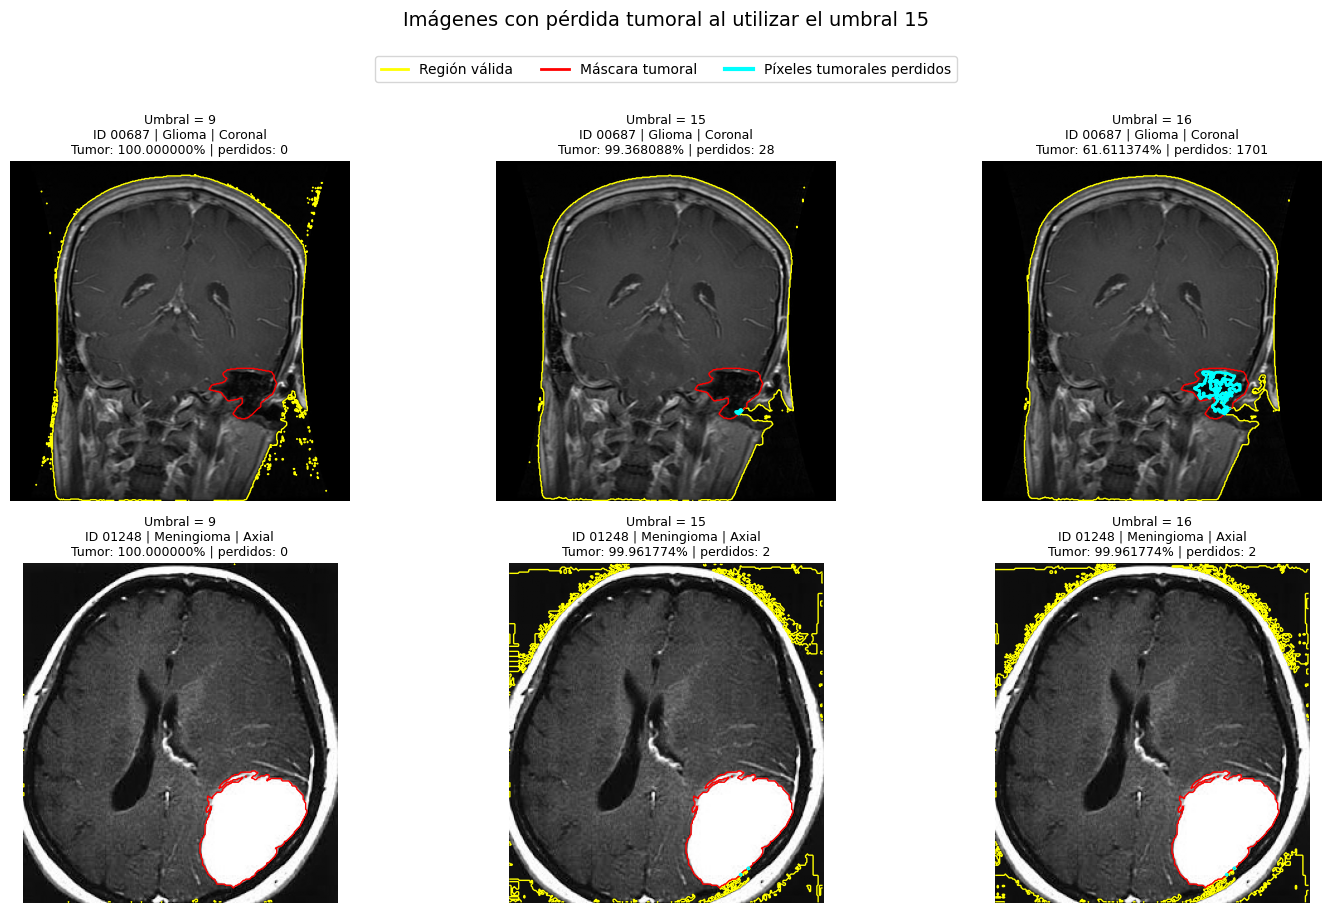

In [14]:
def draw_affected_case(
    axis,
    image,
    tumor_mask,
    threshold,
    title_information,
):
    valid_mask = valid_mask_for_threshold(
        image,
        threshold=threshold,
    )

    lost_tumor_mask = (
        tumor_mask
        & ~valid_mask
    )

    retained_tumor_pixels = int(
        np.logical_and(
            tumor_mask,
            valid_mask,
        ).sum()
    )

    total_tumor_pixels = int(
        tumor_mask.sum()
    )

    lost_tumor_pixels = int(
        lost_tumor_mask.sum()
    )

    tumor_retention = (
        retained_tumor_pixels
        / total_tumor_pixels
    )

    axis.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=255,
    )

    axis.contour(
        valid_mask.astype(float),
        levels=[0.5],
        colors="yellow",
        linewidths=1,
        linestyles="solid",
    )

    axis.contour(
        tumor_mask.astype(float),
        levels=[0.5],
        colors="red",
        linewidths=1,
        linestyles="solid",
    )

    if lost_tumor_mask.any():
        axis.contour(
            lost_tumor_mask.astype(float),
            levels=[0.5],
            colors="cyan",
            linewidths=2,
            linestyles="solid",
        )

    axis.set_title(
        f"Umbral = {threshold}\n"
        f"{title_information}\n"
        f"Tumor: {tumor_retention:.6%} | "
        f"perdidos: {lost_tumor_pixels}",
        fontsize=9,
    )

    axis.axis("off")


if affected_at_15_df.empty:
    print(
        "Ninguna imagen presenta pérdida tumoral "
        "con el umbral 15."
    )

else:
    affected_thresholds = [
        REFERENCE_THRESHOLD,
        SELECTED_THRESHOLD,
        DETERIORATION_THRESHOLD,
    ]

    figure, axes = plt.subplots(
        nrows=len(affected_at_15_df),
        ncols=len(affected_thresholds),
        figsize=(
            15,
            4.5 * len(affected_at_15_df),
        ),
    )

    if len(affected_at_15_df) == 1:
        axes = np.array([
            axes
        ])

    for row_position, row in enumerate(
        affected_at_15_df.itertuples(
            index=False
        )
    ):
        image = load_grayscale(
            row.image_path
        )

        mask_image = load_grayscale(
            row.mask_path
        )

        tumor_mask = (
            mask_image
            > MASK_THRESHOLD
        )

        title_information = (
            f"ID {row.image_id} | "
            f"{row.tumor_label} | "
            f"{row.plane_label}"
        )

        for column_position, threshold in enumerate(
            affected_thresholds
        ):
            draw_affected_case(
                axis=axes[
                    row_position,
                    column_position,
                ],
                image=image,
                tumor_mask=tumor_mask,
                threshold=threshold,
                title_information=(
                    title_information
                ),
            )
        legend_elements = [
        Line2D(
            [0],
            [0],
            color="yellow",
            linewidth=2,
            linestyle="solid",
            label="Región válida",
        ),
        Line2D(
            [0],
            [0],
            color="red",
            linewidth=2,
            linestyle="solid",
            label="Máscara tumoral",
        ),
        Line2D(
            [0],
            [0],
            color="cyan",
            linewidth=3,
            linestyle="solid",
            label="Píxeles tumorales perdidos",
        ),
    ]

    figure.legend(
        handles=legend_elements,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.965),
        ncol=3,
        fontsize=10,
        frameon=True,
    )
    figure.suptitle(
        (
            "Imágenes con pérdida tumoral "
            "al utilizar el umbral 15"
        ),
        fontsize=14,
        y=1.01,
    )

    plt.tight_layout(
        rect=[
            0,
            0,
            1,
            0.95,
        ],h_pad=1.0,
    )

    plt.savefig(
        FIGURES_DIR
        / "imagenes_afectadas_umbral_15.png",
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )

    plt.show()

## 12. Comparación visual de ejemplos seleccionados

Se visualiza un subconjunto fijo de la muestra aleatoria para comparar los contornos de las regiones válidas obtenidas con los tres umbrales de referencia.

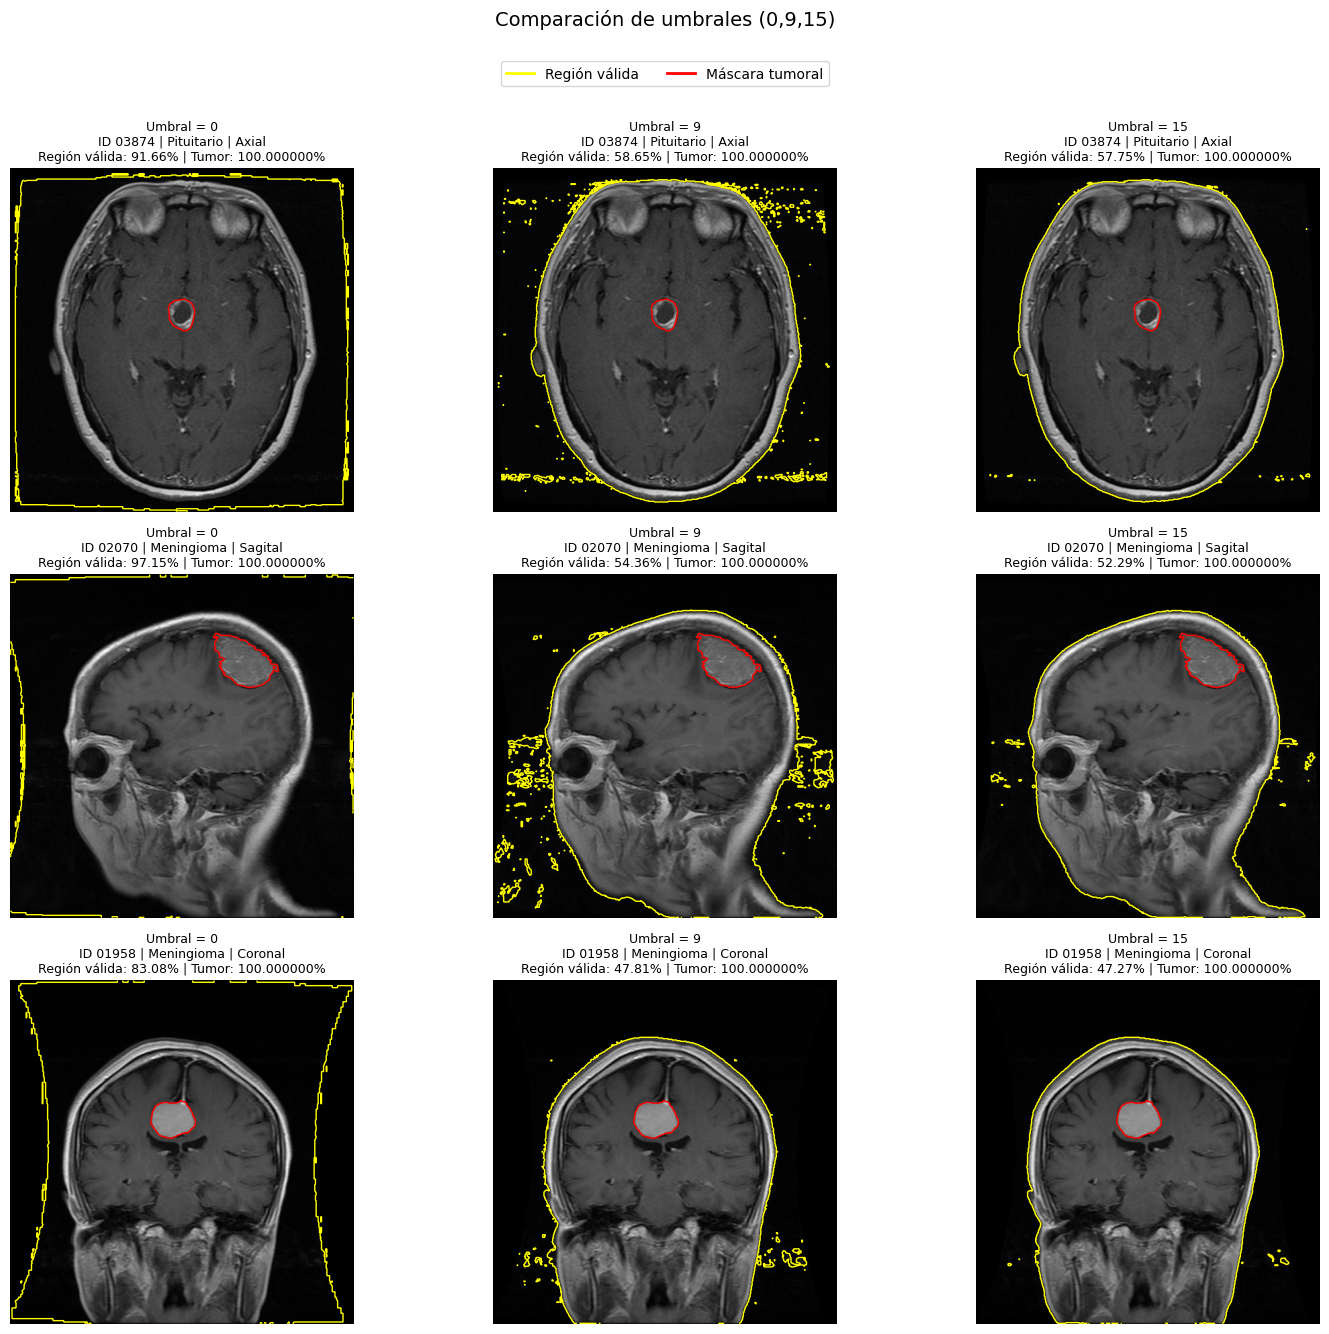

In [15]:
SELECTED_ROWS = [
    4,
    6,
    9,
]

if max(SELECTED_ROWS) > len(random_examples_df):
    raise ValueError("La selección supera el número de ejemplos disponibles.")

selected_examples_df = random_examples_df.iloc[
    [
        row_number - 1
        for row_number in SELECTED_ROWS
    ]
].copy()


figure, axes = plt.subplots(
    nrows=len(selected_examples_df),
    ncols=len(EXAMPLE_THRESHOLDS),
    figsize=(
        15,
        4.5 * len(selected_examples_df),
    ),
)


if len(selected_examples_df) == 1:
    axes = np.array([
        axes
    ])


for row_position, row in enumerate(
    selected_examples_df.itertuples(
        index=False
    )
):
    image = load_grayscale(
        row.image_path
    )

    mask_image = load_grayscale(
        row.mask_path
    )

    tumor_mask = (
        mask_image > MASK_THRESHOLD
    )

    title_information = (
        f"ID {row.image_id} | "
        f"{row.tumor_label} | "
        f"{row.plane_label}"
    )

    for column_position, threshold in enumerate(
        EXAMPLE_THRESHOLDS
    ):
        draw_threshold_example(
            axis=axes[
                row_position,
                column_position,
            ],
            image=image,
            tumor_mask=tumor_mask,
            threshold=threshold,
            title_information=(
                title_information
            ),
        )


legend_elements = [
    Line2D(
        [0],
        [0],
        color="yellow",
        linewidth=2,
        linestyle="solid",
        label="Región válida",
    ),
    Line2D(
        [0],
        [0],
        color="red",
        linewidth=2,
        linestyle="solid",
        label="Máscara tumoral",
    ),
]


figure.suptitle(
    "Comparación de umbrales (0,9,15)",
    fontsize=14,
    y=0.985,
)


figure.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.952,
    ),
    ncol=2,
    fontsize=10,
    frameon=True,
)


plt.tight_layout(
    rect=[
        0,
        0,
        1,
        0.94,
    ],
    h_pad=1.0,
)


plt.savefig(
    FIGURES_DIR
    / "comparacion_umbrales_ejemplos_seleccionados.png",
    dpi=FIGURE_DPI,
    bbox_inches="tight",
)


plt.show()


## 13. Resumen numérico de resultados

Se reúnen las medidas de conservación y pérdida tumoral correspondientes a los umbrales utilizados en la comparación.


In [16]:
# Indicadores numéricos derivados de las tablas anteriores.
indicadores_resumen = pd.DataFrame([
    {
        "umbral": int(fila["threshold"]),
        "n_imagenes": int(fila["n_images"]),
        "pixeles_tumorales": int(fila["total_tumor_pixels"]),
        "pixeles_tumorales_excluidos": int(fila["total_lost_tumor_pixels"]),
        "imagenes_con_perdida": int(fila["images_with_tumor_loss"]),
        "conservacion_global_pct": 100.0 * float(fila["global_tumor_retention"]),
        "conservacion_minima_pct": 100.0 * float(fila["minimum_tumor_retention"]),
    }
    for _, fila in summary_df.loc[summary_df["threshold"].isin(DECISION_THRESHOLDS)].iterrows()
])
indicadores_resumen.to_csv(
    TABLES_DIR / "resumen_numerico_umbrales_referencia.csv",
    index=False,
    encoding="utf-8-sig",
)
display(indicadores_resumen)


,umbral,n_imagenes,pixeles_tumorales,pixeles_tumorales_excluidos,imagenes_con_perdida,conservacion_global_pct,conservacion_minima_pct
0,0,3792,15496552,0,0,100.000000,100.000000
1,9,3792,15496552,0,0,100.000000,100.000000
2,15,3792,15496552,30,2,99.999806,99.368088
3,16,3792,15496552,1706,3,99.988991,61.611374


## 14. Registro de configuración

Se guardan los parámetros del análisis y las versiones de las bibliotecas principales.


In [17]:
configuration = {
    "base_dir": "data/BRISC2025/segmentation_task/train",
    "images_dir": "data/BRISC2025/segmentation_task/train/images",
    "masks_dir": "data/BRISC2025/segmentation_task/train/masks",
    "output_dir": "results/OE0/seleccion_umbral_Ri_BRISC",
    "mask_threshold": MASK_THRESHOLD,
    "max_images": MAX_IMAGES,
    "random_seed": RANDOM_SEED,
    "min_threshold": MIN_THRESHOLD,
    "max_threshold": MAX_THRESHOLD,
    "reference_threshold": (
        REFERENCE_THRESHOLD
    ),
    "selected_threshold": (
        SELECTED_THRESHOLD
    ),
    "deterioration_threshold": (
        DETERIORATION_THRESHOLD
    ),
    "example_thresholds": (
        EXAMPLE_THRESHOLDS
    ),
    "n_random_examples": (
        N_RANDOM_EXAMPLES
    ),
    "random_example_seed": (
        RANDOM_EXAMPLE_SEED
    ),
}

environment = {
    "python": (
        platform.python_version()
    ),
    "platform": (
        platform.platform()
    ),
    "numpy": np.__version__,
    "pandas": pd.__version__,
}

with open(
    OUTPUT_DIR
    / "configuracion_analisis.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        configuration,
        file,
        ensure_ascii=False,
        indent=2,
    )

with open(
    OUTPUT_DIR
    / "versiones_entorno.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        environment,
        file,
        ensure_ascii=False,
        indent=2,
    )

print("Análisis terminado.")
print(
    f"Umbral seleccionado: "
    f"{SELECTED_THRESHOLD}"
)
print(
    f"Resultados guardados en: "
    f"{OUTPUT_DIR}"
)


Análisis terminado.
Umbral seleccionado: 15
Resultados guardados en: K:\Tesis\Github\results\OE0\seleccion_umbral_Ri_BRISC
